# 3. Exploratory Data Analysis

This notebook explores the four-year Open-Meteo Hanoi dataset before modeling.

Because the study now spans **four complete annual cycles**, the EDA places more emphasis on:

1. PM2.5 distribution and extreme episodes;
2. long-term temporal variation;
3. recurring month-of-year patterns across years;
4. local-hour patterns;
5. associations with the 6-hour-ahead PM2.5 target.

The goal is descriptive understanding, not causal inference.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROCESSED_DIR = Path("../data/processed")

df_model = pd.read_pickle(
    PROCESSED_DIR /
    "hanoi_pm25_model_withna_4y.pkl"
)

# Study year is defined as September -> August so the four-year dataset
# forms four complete and directly comparable annual cycles.
df_model["study_year_start"] = np.where(
    df_model["timestamp_local"].dt.month >= 9,
    df_model["timestamp_local"].dt.year,
    df_model["timestamp_local"].dt.year - 1,
)

df_model["study_year"] = (
    df_model["study_year_start"].astype(int).astype(str)
    + "/"
    + (df_model["study_year_start"] + 1).astype(int).astype(str).str[-2:]
)

STUDY_YEAR_ORDER = ["2022/23", "2023/24", "2024/25", "2025/26"]

df_model.head()


,timestamp_local,timestamp_utc,pm25,pm10,no2,temperature_2m,relative_humidity_2m,precipitation,surface_pressure,wind_speed_10m,...,wind_dir_sin,wind_dir_cos,hour_sin,hour_cos,dow_sin,dow_cos,month_sin,month_cos,study_year_start,study_year
0,2022-09-01 00:00:00+07:00,2022-08-31 17:00:00+00:00,71.5,103.1,29.1,27.6,91.0,0.0,1006.6,1.70,...,-0.052336,-0.998630,0.000000,1.000000,0.433884,-0.900969,-0.866025,-0.5,2022,2022/23
1,2022-09-01 01:00:00+07:00,2022-08-31 18:00:00+00:00,62.4,89.9,25.5,27.3,93.0,0.0,1006.2,0.99,...,0.707107,-0.707107,0.258819,0.965926,0.433884,-0.900969,-0.866025,-0.5,2022,2022/23
2,2022-09-01 02:00:00+07:00,2022-08-31 19:00:00+00:00,49.2,71.0,21.8,25.7,94.0,0.5,1006.7,5.59,...,0.484810,0.874620,0.500000,0.866025,0.433884,-0.900969,-0.866025,-0.5,2022,2022/23
3,2022-09-01 03:00:00+07:00,2022-08-31 20:00:00+00:00,36.6,52.9,17.6,24.7,93.0,3.9,1006.8,4.64,...,0.798636,0.601815,0.707107,0.707107,0.433884,-0.900969,-0.866025,-0.5,2022,2022/23
4,2022-09-01 04:00:00+07:00,2022-08-31 21:00:00+00:00,28.7,41.6,13.2,24.5,96.0,0.9,1007.3,4.57,...,0.484810,0.874620,0.866025,0.500000,0.433884,-0.900969,-0.866025,-0.5,2022,2022/23


## 1. Distribution of PM2.5 concentrations

In [2]:
distribution_stats = df_model["pm25"].describe()
skewness = df_model["pm25"].skew()

display(distribution_stats)
print("Skewness:", round(skewness, 3))

count    35064.000000
mean        45.438969
std         27.653881
min          0.300000
25%         26.300000
50%         38.400000
75%         56.800000
max        232.800000
Name: pm25, dtype: float64

Skewness: 1.55


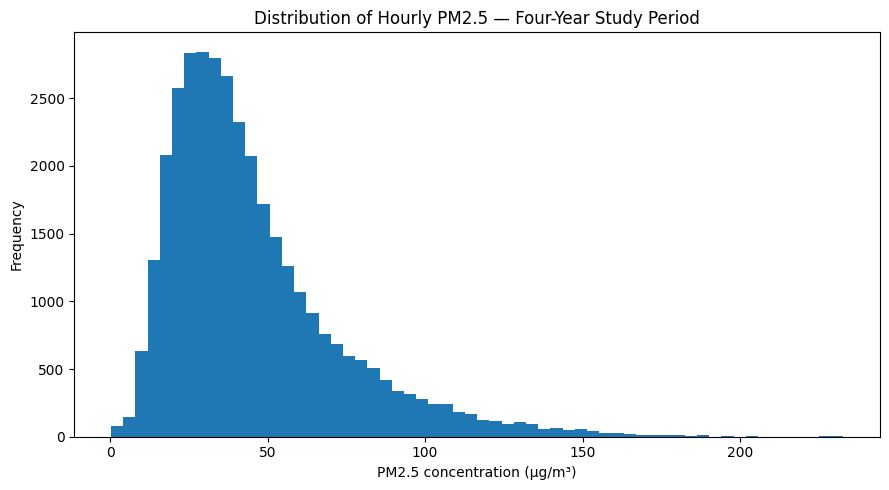

In [3]:
plt.figure(figsize=(9, 5))
plt.hist(
    df_model["pm25"].dropna(),
    bins=60,
)
plt.xlabel("PM2.5 concentration (µg/m³)")
plt.ylabel("Frequency")
plt.title("Distribution of Hourly PM2.5 — Four-Year Study Period")
plt.tight_layout()
plt.show()

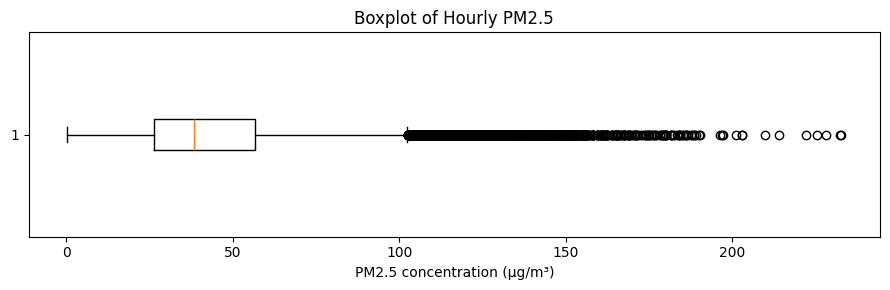

In [4]:
plt.figure(figsize=(9, 3))
plt.boxplot(
    df_model["pm25"].dropna(),
    vert=False,
)
plt.xlabel("PM2.5 concentration (µg/m³)")
plt.title("Boxplot of Hourly PM2.5")
plt.tight_layout()
plt.show()

High values above a statistical outlier threshold are not automatically treated as errors. They may represent genuine high-pollution conditions in the gridded air-quality product.

## 2. Temporal variation across the four-year study period

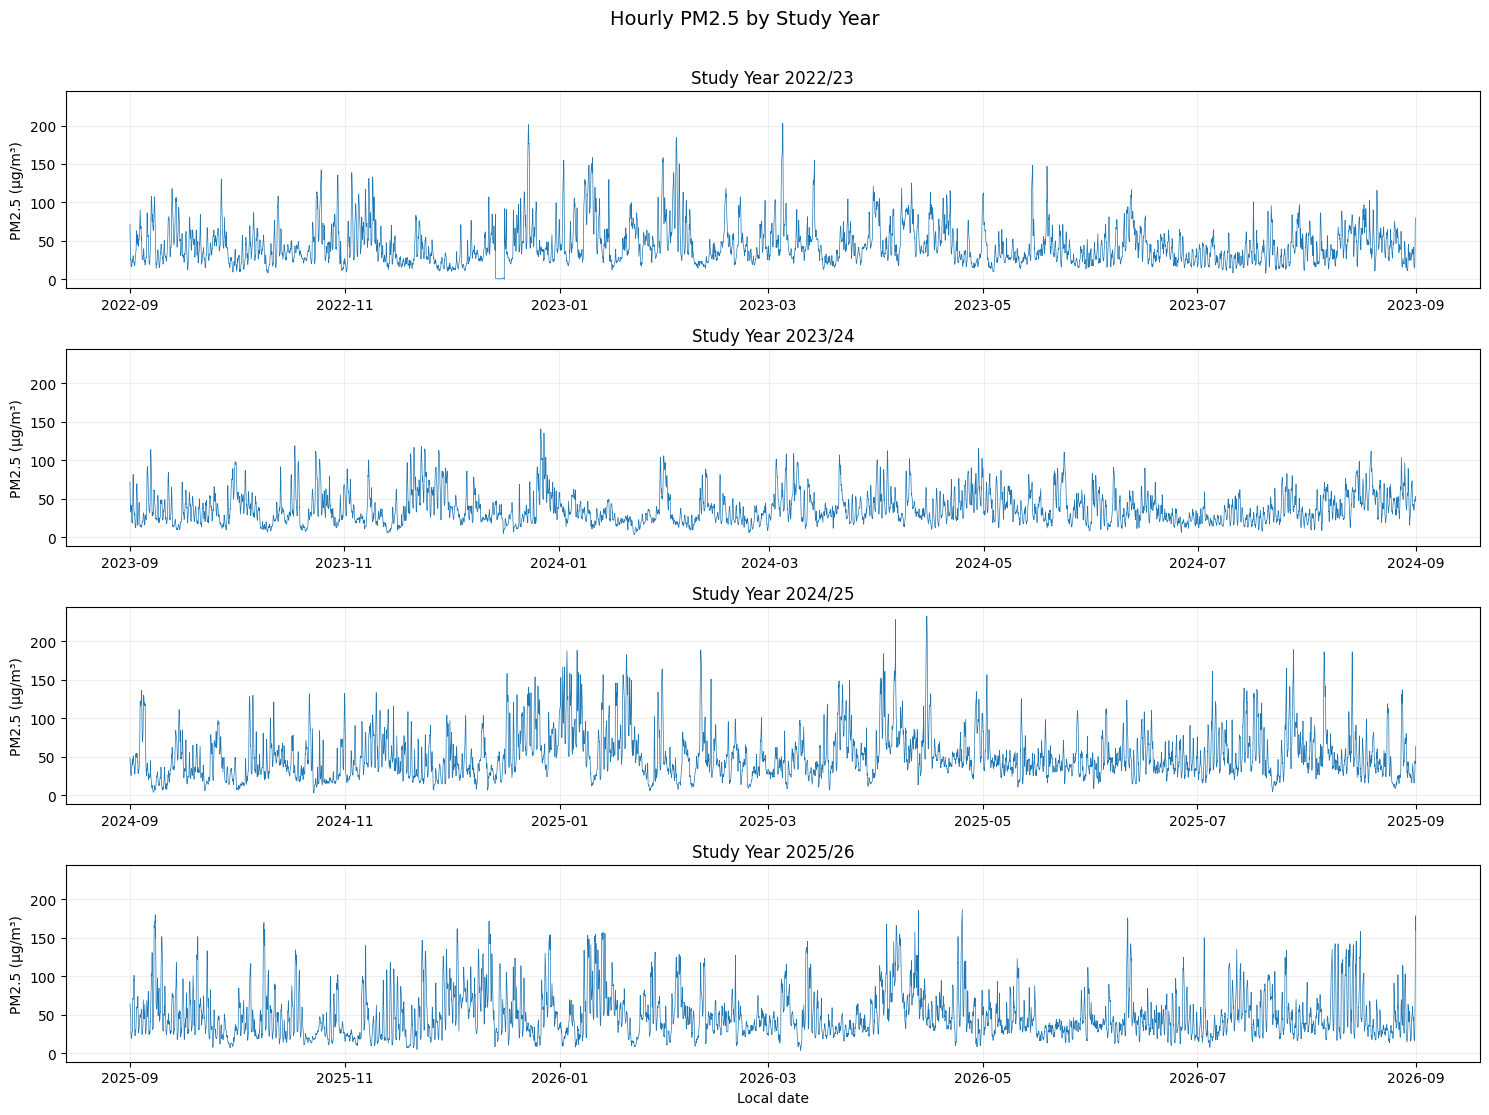

In [5]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(15, 11),
    sharey=True,
)

for ax, study_year in zip(axes, STUDY_YEAR_ORDER):
    subset = df_model.loc[
        df_model["study_year"] == study_year,
        ["timestamp_local", "pm25"],
    ]

    ax.plot(
        subset["timestamp_local"],
        subset["pm25"],
        linewidth=0.5,
    )
    ax.set_title(f"Study Year {study_year}")
    ax.set_ylabel("PM2.5 (µg/m³)")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Local date")
fig.suptitle(
    "Hourly PM2.5 by Study Year",
    y=1.01,
    fontsize=14,
)
plt.tight_layout()
plt.show()


### Daily means with minimum 75% hourly coverage

Hourly PM2.5 is aggregated into daily means only when at least **18 of 24 hourly values** are available.  
The four study years are plotted separately to avoid compressing the entire four-year series into one dense line.

A **7-day rolling mean** is added only as a visual smoothing aid; the unsmoothed daily mean remains visible.


In [6]:
daily_pm25 = (
    df_model
    .set_index("timestamp_local")["pm25"]
    .resample("D")
    .agg(["mean", "count"])
    .rename(columns={
        "mean": "pm25_mean",
        "count": "observed_hours",
    })
)

daily_pm25["pm25_mean_valid"] = (
    daily_pm25["pm25_mean"]
    .where(daily_pm25["observed_hours"] >= 18)
)

daily_pm25["study_year_start"] = np.where(
    daily_pm25.index.month >= 9,
    daily_pm25.index.year,
    daily_pm25.index.year - 1,
)

daily_pm25["study_year"] = (
    daily_pm25["study_year_start"].astype(int).astype(str)
    + "/"
    + (daily_pm25["study_year_start"] + 1).astype(int).astype(str).str[-2:]
)

# Compute rolling means within each study year so smoothing does not cross
# the Sep/Aug study-year boundary.
daily_pm25["pm25_7d_mean"] = (
    daily_pm25
    .groupby("study_year")["pm25_mean_valid"]
    .transform(lambda s: s.rolling(window=7, min_periods=4).mean())
)

print("Total days:", len(daily_pm25))
print(
    "Days meeting >=18 observed hours:",
    int(daily_pm25["pm25_mean_valid"].notna().sum()),
)


Total days: 1461
Days meeting >=18 observed hours: 1461


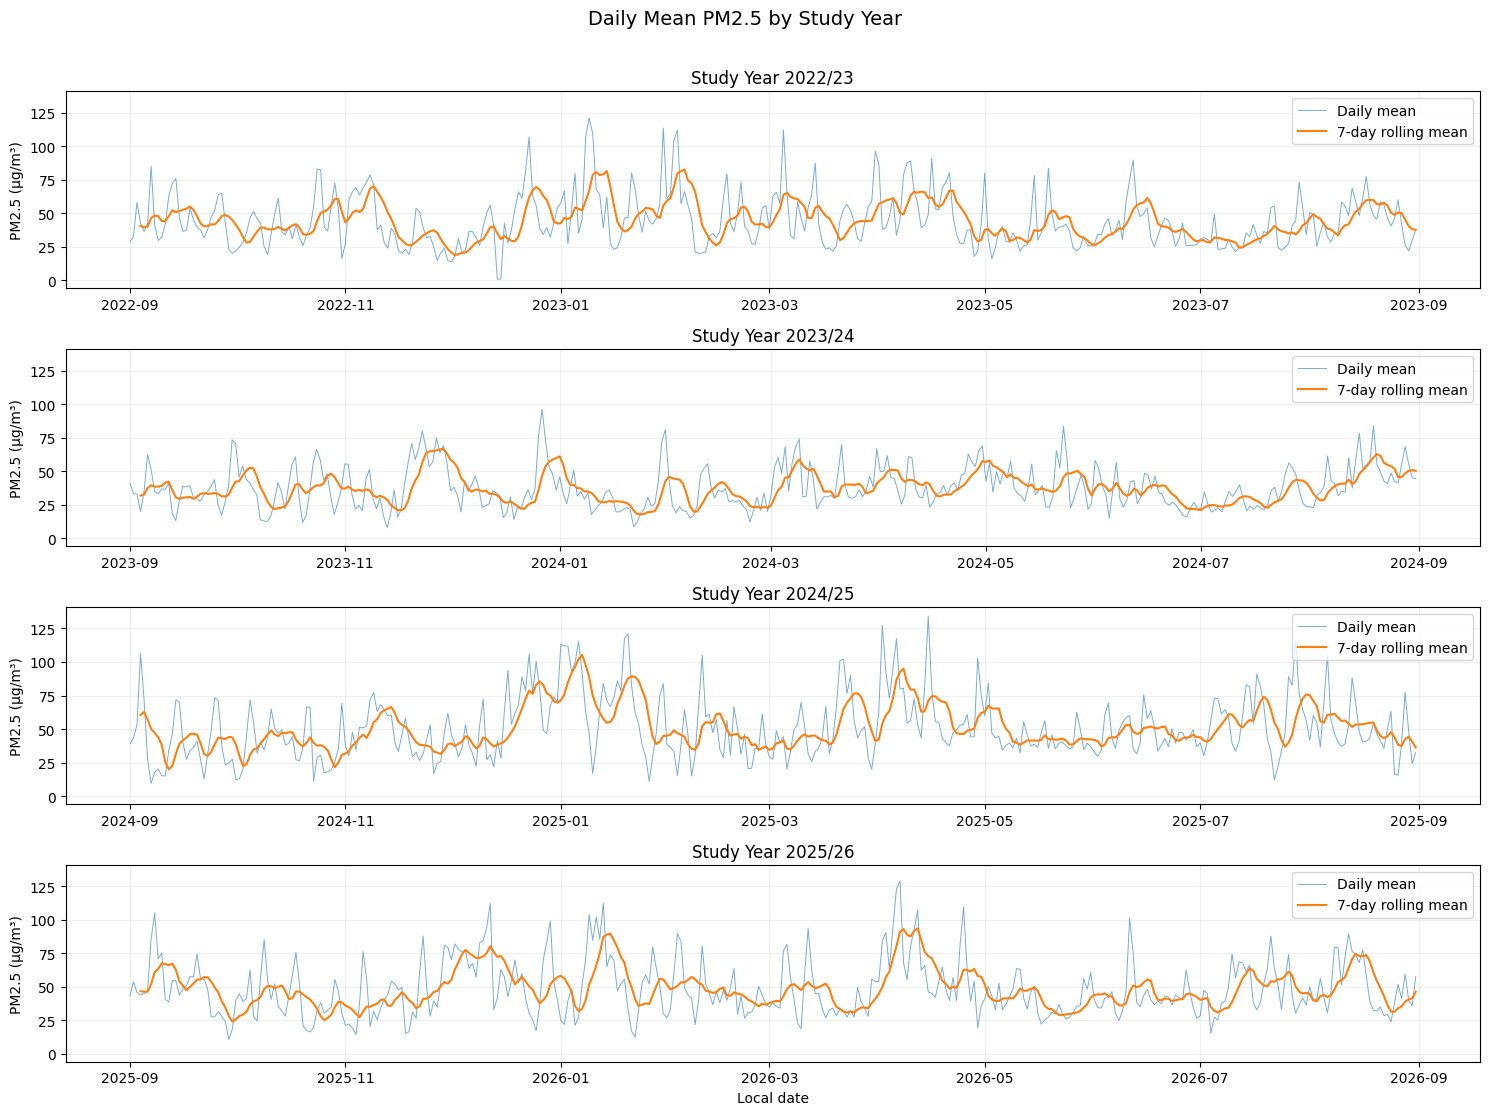

In [7]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=1,
    figsize=(15, 11),
    sharey=True,
)

for ax, study_year in zip(axes, STUDY_YEAR_ORDER):
    subset = daily_pm25.loc[
        daily_pm25["study_year"] == study_year
    ]

    ax.plot(
        subset.index,
        subset["pm25_mean_valid"],
        linewidth=0.7,
        alpha=0.6,
        label="Daily mean",
    )
    ax.plot(
        subset.index,
        subset["pm25_7d_mean"],
        linewidth=1.5,
        label="7-day rolling mean",
    )

    ax.set_title(f"Study Year {study_year}")
    ax.set_ylabel("PM2.5 (µg/m³)")
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Local date")
fig.suptitle(
    "Daily Mean PM2.5 by Study Year",
    y=1.01,
    fontsize=14,
)
plt.tight_layout()
plt.show()


### Monthly mean time series

Monthly aggregation makes the repeated annual structure easier to inspect without claiming that every month behaves identically across years.

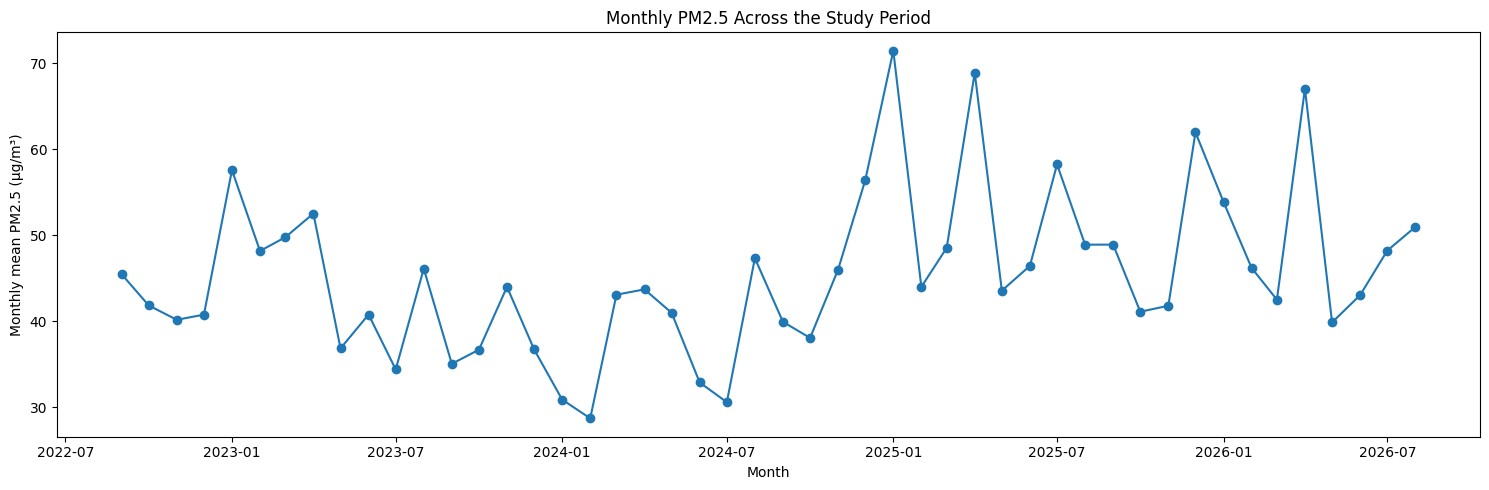

In [8]:
monthly_pm25 = (
    df_model
    .set_index("timestamp_local")["pm25"]
    .resample("MS")
    .agg(["mean", "count"])
    .rename(columns={
        "mean": "pm25_mean",
        "count": "observed_hours",
    })
)

plt.figure(figsize=(15, 5))
plt.plot(
    monthly_pm25.index,
    monthly_pm25["pm25_mean"],
    marker="o",
)
plt.xlabel("Month")
plt.ylabel("Monthly mean PM2.5 (µg/m³)")
plt.title("Monthly PM2.5 Across the Study Period")
plt.tight_layout()
plt.show()

## 3. Recurring month-of-year pattern

The next views examine whether PM2.5 exhibits a recurring annual pattern across the four complete **September–August study years**.


In [9]:
eda = df_model.copy()
eda["year"] = eda["timestamp_local"].dt.year
eda["month"] = eda["timestamp_local"].dt.month
eda["hour_local"] = eda["timestamp_local"].dt.hour

month_summary = (
    eda
    .groupby("month")["pm25"]
    .agg(["mean", "median", "std", "count"])
)

month_summary


,mean,median,std,count
month,,,,
1,53.433065,42.60,36.219071,2976
2,41.648894,36.15,25.541797,2712
3,45.964382,39.80,25.295916,2976
4,58.019028,50.10,31.302588,2880
5,40.303831,36.10,19.638594,2976
6,40.779410,36.90,20.683927,2880
7,42.849059,35.60,26.462231,2976
8,48.317372,42.80,25.753381,2976
9,42.334757,35.60,25.958788,2880


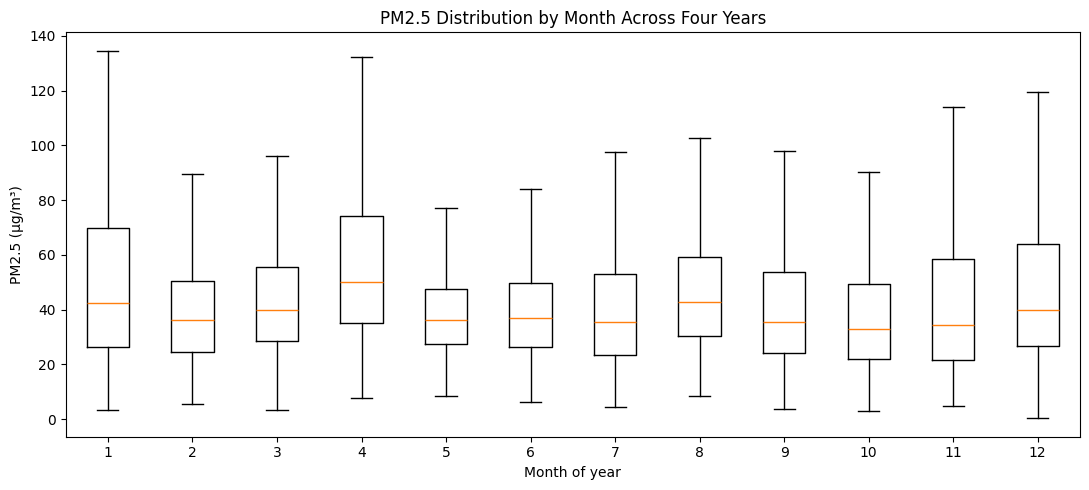

In [10]:
month_data = [
    eda.loc[eda["month"] == m, "pm25"].dropna()
    for m in range(1, 13)
]

plt.figure(figsize=(11, 5))
plt.boxplot(
    month_data,
    tick_labels=list(range(1, 13)),
    showfliers=False,
)
plt.xlabel("Month of year")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("PM2.5 Distribution by Month Across Four Years")
plt.tight_layout()
plt.show()

### Monthly PM2.5 pattern across study years

Instead of comparing incomplete calendar years (2022 and 2026 are only partial years in this dataset), the heatmap compares the four complete **September–August study years**.

Each cell is the mean PM2.5 concentration for one month within one study year. This makes repeated or changing seasonal structure easier to inspect.


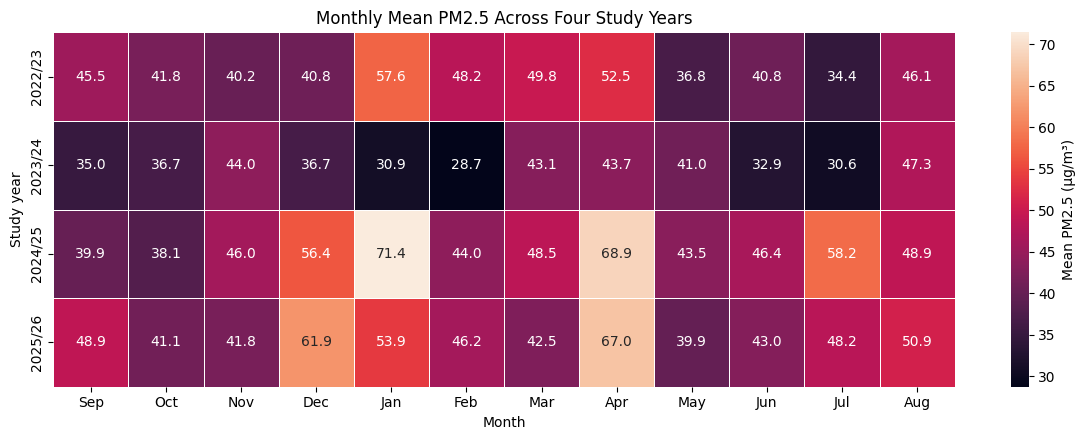

In [11]:
MONTH_ORDER = [9, 10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8]
MONTH_LABELS = [
    "Sep", "Oct", "Nov", "Dec",
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
]

study_month = (
    eda
    .groupby(["study_year", "month"])["pm25"]
    .mean()
    .unstack("month")
    .reindex(index=STUDY_YEAR_ORDER, columns=MONTH_ORDER)
)

study_month.columns = MONTH_LABELS

plt.figure(figsize=(12, 4.5))
sns.heatmap(
    study_month,
    annot=True,
    fmt=".1f",
    linewidths=0.5,
    cbar_kws={"label": "Mean PM2.5 (µg/m³)"},
)
plt.xlabel("Month")
plt.ylabel("Study year")
plt.title("Monthly Mean PM2.5 Across Four Study Years")
plt.tight_layout()
plt.show()


## 4. Local hour-of-day pattern

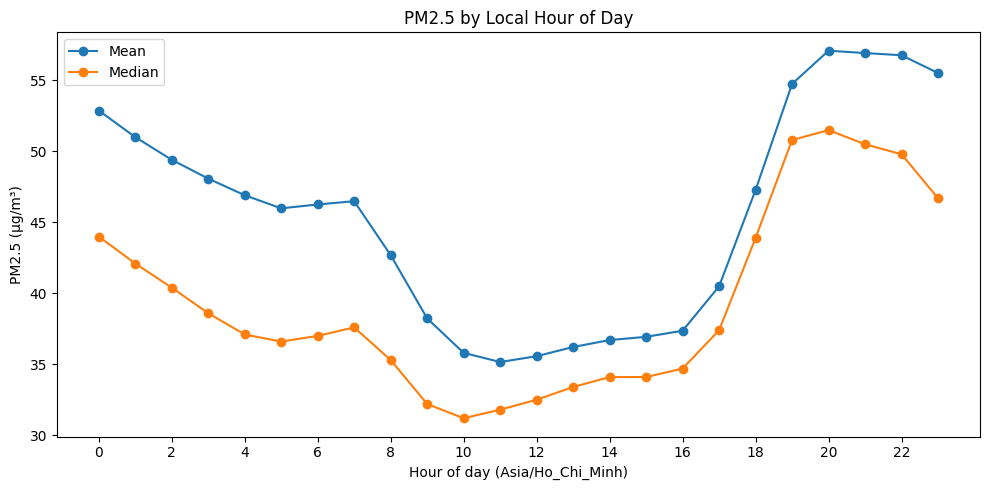

In [12]:
hourly_pattern = (
    eda
    .groupby("hour_local")["pm25"]
    .agg(["mean", "median", "count"])
)

plt.figure(figsize=(10, 5))
plt.plot(
    hourly_pattern.index,
    hourly_pattern["mean"],
    marker="o",
    label="Mean",
)
plt.plot(
    hourly_pattern.index,
    hourly_pattern["median"],
    marker="o",
    label="Median",
)
plt.xticks(range(0, 24, 2))
plt.xlabel("Hour of day (Asia/Ho_Chi_Minh)")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("PM2.5 by Local Hour of Day")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Relationships with the 6-hour-ahead target

Pearson correlation describes pairwise linear association. It is not a causal estimate and does not by itself establish that a predictor adds incremental forecasting value.

In [17]:
candidate_predictors = [
    "pm25",
    "pm25_lag1",
    "pm25_lag2",
    "pm25_lag3",
    "pm25_lag6",
    "pm25_lag12",
    "pm25_lag18",
    "pm25_lag24",
    "pm10",
    "no2",
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "surface_pressure",
    "wind_speed_10m",
    "wind_dir_sin",
    "wind_dir_cos",
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos",
]

target = "pm25_t_plus_6"

target_corr = (
    df_model[candidate_predictors + [target]]
    .corr(numeric_only=True)[target]
    .drop(target)
    .sort_values()
)

target_corr

wind_speed_10m         -0.380849
hour_sin               -0.249448
relative_humidity_2m   -0.175088
wind_dir_cos           -0.153345
precipitation          -0.103235
hour_cos               -0.040044
wind_dir_sin            0.001100
dow_sin                 0.014970
dow_cos                 0.015979
surface_pressure        0.017119
temperature_2m          0.020695
month_sin               0.050348
month_cos               0.066160
pm25_lag24              0.307967
no2                     0.314159
pm25_lag6               0.321943
pm25_lag12              0.376757
pm25_lag3               0.404624
pm25_lag2               0.452639
pm25_lag1               0.511286
pm10                    0.532713
pm25_lag18              0.548363
pm25                    0.579466
Name: pm25_t_plus_6, dtype: float64

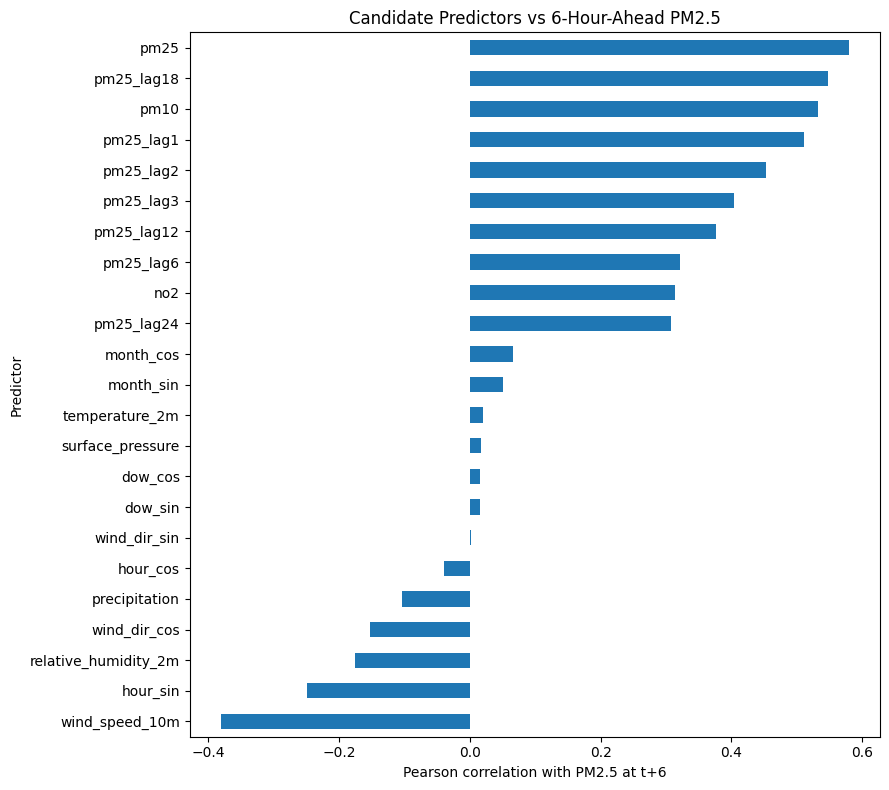

In [18]:
plt.figure(figsize=(9, 8))
target_corr.plot(kind="barh")
plt.xlabel("Pearson correlation with PM2.5 at t+6")
plt.ylabel("Predictor")
plt.title("Candidate Predictors vs 6-Hour-Ahead PM2.5")
plt.tight_layout()
plt.show()

## 6. Predictor correlation and redundancy

This heatmap focuses on pairwise Pearson correlations among the main numerical predictors.  
A diverging red–blue scale is used so positive and negative correlations are visually distinct, with coefficients shown directly in each cell.


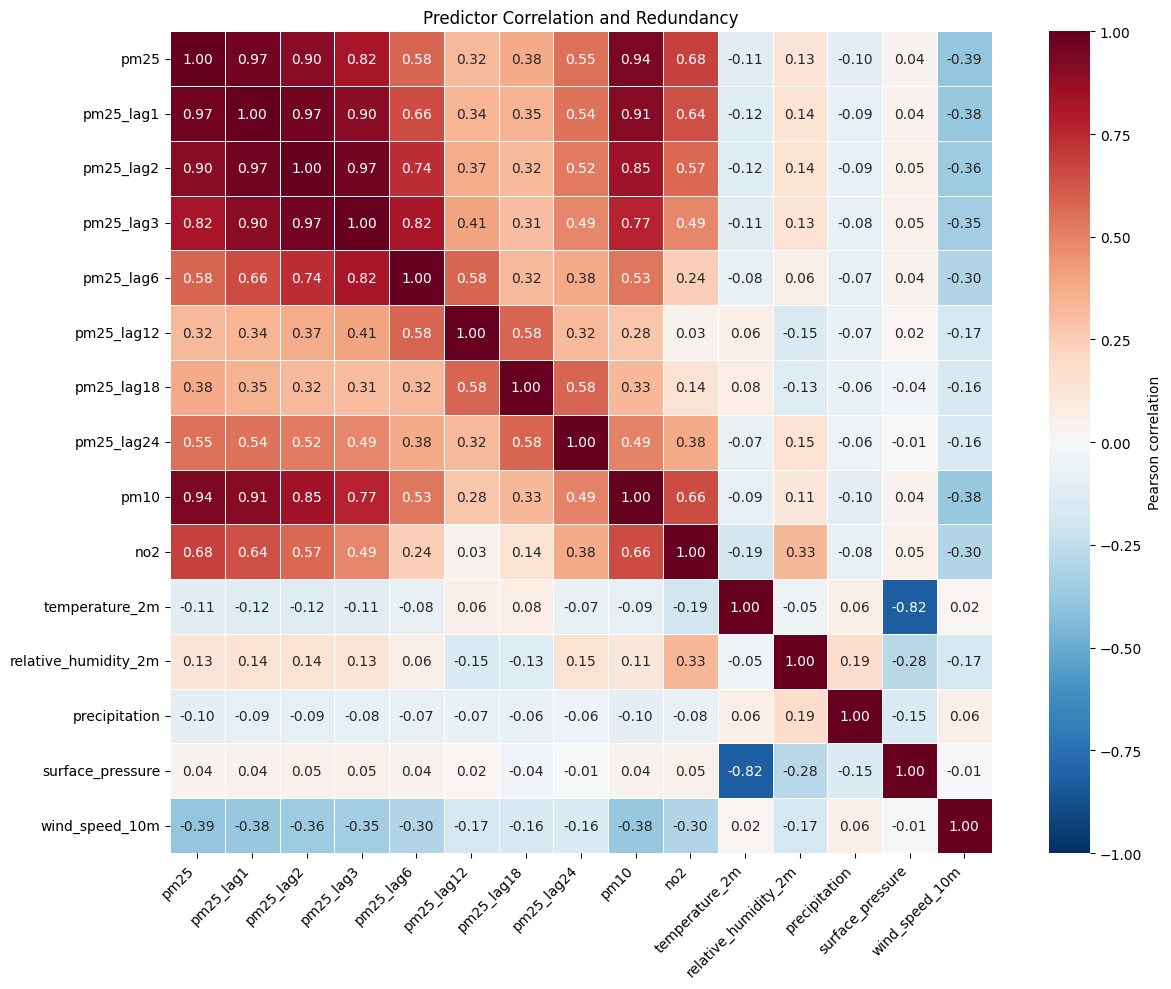

In [19]:
corr_features = [
    "pm25",
    "pm25_lag1",
    "pm25_lag2",
    "pm25_lag3",
    "pm25_lag6",
    "pm25_lag12",
    "pm25_lag18",
    "pm25_lag24",
    "pm10",
    "no2",
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "surface_pressure",
    "wind_speed_10m",
]

corr_matrix = (
    df_model[corr_features]
    .corr(numeric_only=True)
)

plt.figure(figsize=(13, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson correlation"},
)
plt.title("Predictor Correlation and Redundancy")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 7. EDA outcome

The four-year EDA is used to assess:

- whether hourly PM2.5 remains strongly right-skewed;
- how short-term and daily PM2.5 variation differs across the four complete study years;
- whether month-of-year patterns recur across annual cycles;
- whether local-hour patterns are evident in Hanoi local time;
- which candidate predictors have linear association with the `t+6` target;
- where strong predictor redundancy may motivate regularization or nonlinear models.

The EDA is descriptive. Feature inclusion and model choice are determined using the validation period in the modeling notebook rather than correlation alone.
